<div dir="rtl">

# تشخیص حملات SQL Injection با یادگیری عمیق
## مدل ترکیبی Word2Vec/TF-IDF ← TextCNN بهبودیافته ← BiLSTM ← Attention

این نوت‌بوک پیاده‌سازی روش مقاله‌ی زیر است:

> **H. Sun, Y. Du, Q. Li**, "Deep Learning-Based Detection Technology for SQL Injection Research and Implementation",
> *Applied Sciences*, vol. 13, no. 16, p. 9466, 2023. DOI: [10.3390/app13169466](https://doi.org/10.3390/app13169466)
> (MDPI — JCR Q2)

**ایده‌ی اصلی مقاله:**
1. بردارسازی کوئری‌ها با ترکیب (fusion) **TF-IDF** و **Word2Vec**
2. استخراج ویژگی‌های محلی (local features) با یک **TextCNN بهبودیافته**
3. مدل‌سازی ترتیب توکن‌ها با **Bi-LSTM**
4. لایه‌ی **Attention** روی خروجی LSTM برای جبران ضعف LSTM در دنباله‌های طولانی
5. طبقه‌بندی دودویی: کوئری سالم (0) / SQLi (1)

**دیتاست:** [SQL Injection Dataset — Kaggle (sajid576)](https://www.kaggle.com/datasets/sajid576/sql-injection-dataset)، فایل `Modified_SQL_Dataset.csv`
(۳۰٬۹۱۹ کوئری). مقاله‌ی اصلی از دیتاست خصوصیِ تولیدشده توسط ابزار خود نویسندگان استفاده کرده؛ اینجا همان روش روی دیتاست عمومی Kaggle اجرا می‌شود.

**نکته‌ی شفافیت:** بعضی هایپرپارامترها (اندازه‌ی کرنل‌ها، تعداد فیلترها، ابعاد لایه‌ها) در بخش‌های در دسترس مقاله ذکر نشده بودند؛
مقادیر انتخاب‌شده در بخش «تنظیمات» آمده و همه قابل تغییرند.

**فهرست:**
1. تنظیمات و بارگذاری داده
2. پیش‌پردازش و توکنایزر مخصوص SQL
3. Baseline های یادگیری ماشین کلاسیک
4. بردارسازی TF-IDF + Word2Vec
5. تعریف مدل‌ها (مدل پیشنهادی + baseline های عمیق + ablation)
6. آموزش و ارزیابی
7. مقایسه‌ی نتایج، ماتریس درهم‌ریختگی، منحنی ROC
8. تحلیل خطا و نمایش وزن‌های Attention
9. ذخیره‌ی مدل و تابع پیش‌بینی برای کوئری‌های جدید
10. جمع‌بندی و تحلیل نتایج

</div>

<div dir="rtl">

## ۱. تنظیمات و بارگذاری داده

</div>

In [1]:
import hashlib
import json
import math
import random
import re
import shutil
import time
import urllib.request
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from gensim.models import Word2Vec
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, confusion_matrix, f1_score,
                             precision_score, recall_score, roc_auc_score, roc_curve)
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import MultinomialNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import LinearSVC
from torch.utils.data import DataLoader, Dataset

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_DIR, MODEL_DIR, RESULTS_DIR = ROOT / "data", ROOT / "models", ROOT / "results"
for d in (DATA_DIR, MODEL_DIR, RESULTS_DIR):
    d.mkdir(exist_ok=True)

CFG = dict(
    seed=42,
    test_size=0.20, val_size=0.10,       # 70 / 10 / 20 split
    max_len=128,                          # covers >99% of queries (in tokens)
    min_freq=2,                           # vocabulary cut-off
    w2v_dim=100, w2v_window=5, w2v_epochs=15, w2v_sg=1,   # skip-gram
    cnn_kernels=(2, 3, 4, 5), cnn_filters=64,
    lstm_hidden=128, att_dim=128, fc_dim=64, dropout=0.5,
    batch_size=64, lr=1e-3, weight_decay=1e-4, max_epochs=15, patience=3,
    seeds_for_proposed=(42, 7, 2023),     # proposed model is trained with several seeds
)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")


def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


set_seed(CFG["seed"])
print("device:", DEVICE, "| torch", torch.__version__)

device: cpu | torch 2.14.1+cu130


In [2]:
DATA_PATH = DATA_DIR / "Modified_SQL_Dataset.csv"
KAGGLE_ID = "sajid576/sql-injection-dataset"
# public mirror of the same Kaggle file, used only when Kaggle is not reachable
MIRROR_URL = ("https://raw.githubusercontent.com/KabirMalik09/SQL_Injection_Detector/"
              "main/data/Modified_SQL_Dataset.csv")

if not DATA_PATH.exists():
    try:
        import kagglehub
        src = Path(kagglehub.dataset_download(KAGGLE_ID)) / "Modified_SQL_Dataset.csv"
        shutil.copy(src, DATA_PATH)
        print("downloaded from Kaggle")
    except Exception as e:  # no kagglehub / no credentials / no network to Kaggle
        print("Kaggle download failed (%s); using GitHub mirror" % type(e).__name__)
        urllib.request.urlretrieve(MIRROR_URL, DATA_PATH)

print("md5:", hashlib.md5(DATA_PATH.read_bytes()).hexdigest())
raw = pd.read_csv(DATA_PATH)
print(raw.shape)
print(raw.Label.value_counts().rename({0: "benign (0)", 1: "SQLi (1)"}))
raw.sample(8, random_state=1)

md5: 9a8bda09e7e9831c91693be170b48340
(30919, 2)
Label
benign (0)    19537
SQLi (1)      11382
Name: count, dtype: int64


,Query,Label
20129,"SELECT DATE_SUB ( ""2017-06-15"", INTERVAL -2 MO...",0
6023,"1"" ) procedure analyse ( extractvalue ( ...",1
28409,SELECT * FROM brief WHERE lesson NOT BETWEEN '...,0
17908,46269,0
22983,SELECT AVG ( gentle ) FROM continued SELECT SU...,0
25171,"SELECT knifeID AS ID, milk AS string FROM even",0
19447,"SELECT post_id, meta_key, meta_value FROM wp_p...",0
8360,"select count ( * ) from all_users t1,all_...",1


<div dir="rtl">

## ۲. پیش‌پردازش و توکنایزر مخصوص SQL

توکنایزر عادی متن برای SQL مناسب نیست؛ نمادهایی مثل `'`، `--`، `/*`، `||`، `@@` و `=` بار معنایی اصلی حمله را دارند.
بنابراین:
- همه چیز lowercase می‌شود؛
- اعداد ← `<num>` و مقادیر هگز ← `<hex>` (تعمیم‌پذیری بهتر، مثلاً `1=1` و `2=2` یکسان دیده می‌شوند)؛
- عملگرها و علائم هر کدام یک توکن مستقل‌اند.

پاک‌سازی: حذف کوئری‌های تکراری و کوئری‌هایی با برچسب متناقض **قبل از** تقسیم داده تا نشت داده (data leakage) بین train و test رخ ندهد.

</div>

In [3]:
TOKEN_RE = re.compile(
    r"0x[0-9a-f]+|\d+(?:\.\d+)?|[a-z_][a-z0-9_$]*"
    r"|--|/\*|\*/|\|\||&&|<=|>=|<>|!=|:=|@@|[^\s\w]"
)


def sql_tokenize(query):
    out = []
    for t in TOKEN_RE.findall(str(query).lower()):
        if t.startswith("0x"):
            out.append("<hex>")
        elif t[0].isdigit():
            out.append("<num>")
        else:
            out.append(t)
    return out


print(sql_tokenize("admin' OR 1=1 -- "))
print(sql_tokenize("SELECT name FROM users WHERE id = 0x1F /* c */ UNION SELECT @@version"))

['admin', "'", 'or', '<num>', '=', '<num>', '--']
['select', 'name', 'from', 'users', 'where', 'id', '=', '<hex>', '/*', 'c', '*/', 'union', 'select', '@@', 'version']


In [4]:
df = raw.dropna(subset=["Query"]).copy()
df["Query"] = df["Query"].astype(str).str.strip()
df["tokens"] = df["Query"].map(sql_tokenize)
n0 = len(df)
df = df[df["tokens"].str.len() > 0]
conflicting = df.groupby("Query")["Label"].nunique()
conflicting = set(conflicting[conflicting > 1].index)
df = df[~df["Query"].isin(conflicting)].drop_duplicates("Query").reset_index(drop=True)
print(f"rows: {n0} -> {len(df)}  (removed empty / duplicate / {len(conflicting)} conflicting-label queries)")

lens = df["tokens"].str.len()
print("tokens per query: median=%d  p95=%d  p99=%d  max=%d"
      % (lens.median(), lens.quantile(.95), lens.quantile(.99), lens.max()))

train_df, test_df = train_test_split(df, test_size=CFG["test_size"], stratify=df.Label, random_state=CFG["seed"])
train_df, val_df = train_test_split(train_df, test_size=CFG["val_size"] / (1 - CFG["test_size"]),
                                    stratify=train_df.Label, random_state=CFG["seed"])
for name, part in [("train", train_df), ("val", val_df), ("test", test_df)]:
    print(f"{name:5s} {len(part):6d}  SQLi ratio={part.Label.mean():.3f}")
y_train, y_val, y_test = (p.Label.values for p in (train_df, val_df, test_df))

rows: 30919 -> 30843  (removed empty / duplicate / 2 conflicting-label queries)
tokens per query: median=11  p95=51  p99=94  max=943
train  21589  SQLi ratio=0.367
val     3085  SQLi ratio=0.367
test    6169  SQLi ratio=0.367


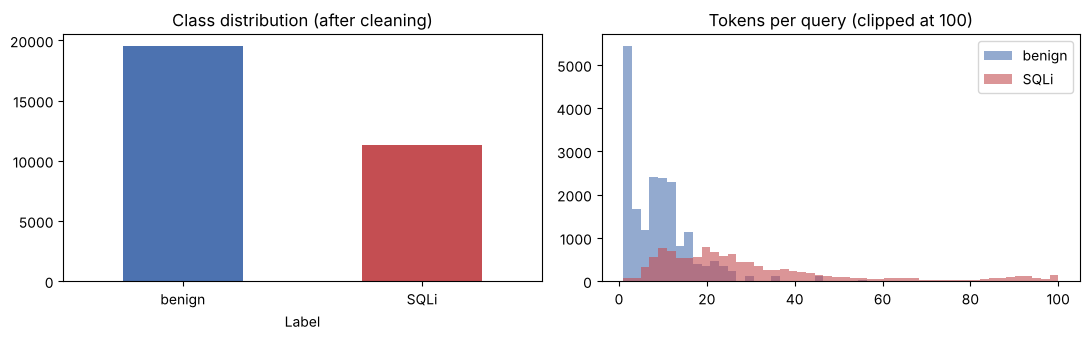

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
df.Label.map({0: "benign", 1: "SQLi"}).value_counts().plot.bar(ax=ax[0], color=["#4C72B0", "#C44E52"])
ax[0].set_title("Class distribution (after cleaning)")
ax[0].tick_params(axis="x", rotation=0)
for lbl, c in [(0, "#4C72B0"), (1, "#C44E52")]:
    ax[1].hist(lens[df.Label == lbl].clip(upper=100), bins=50, alpha=.6, color=c, label=["benign", "SQLi"][lbl])
ax[1].set_title("Tokens per query (clipped at 100)")
ax[1].legend()
plt.tight_layout()
plt.savefig(RESULTS_DIR / "data_overview.png", dpi=120)
plt.show()

<div dir="rtl">

## ۳. Baseline های یادگیری ماشین کلاسیک

مقاله‌ی Sun و همکاران مدل پیشنهادی را با روش‌های کلاسیک (مثل KNN) مقایسه کرده است. اینجا همین کار با ویژگی TF-IDF روی توکن‌های SQL انجام می‌شود
(تقریباً همان رویکرد پروژه‌های ML سنتی).

</div>

In [6]:
def metrics(y_true, y_pred, y_score=None):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    m = dict(Accuracy=accuracy_score(y_true, y_pred), Precision=precision_score(y_true, y_pred, zero_division=0),
             Recall=recall_score(y_true, y_pred), F1=f1_score(y_true, y_pred),
             FPR=fp / (fp + tn), FNR=fn / (fn + tp))
    m["AUC"] = roc_auc_score(y_true, y_score) if y_score is not None else np.nan
    return m


tfidf = TfidfVectorizer(tokenizer=sql_tokenize, token_pattern=None, lowercase=False, ngram_range=(1, 2), min_df=2)
Xtr_tfidf = tfidf.fit_transform(train_df.Query)
Xte_tfidf = tfidf.transform(test_df.Query)
print("TF-IDF features:", Xtr_tfidf.shape[1])

classic = {
    "KNN (k=5)": KNeighborsClassifier(n_neighbors=5),
    "Naive Bayes": MultinomialNB(),
    "Logistic Regression": LogisticRegression(max_iter=2000),
    "Linear SVM": LinearSVC(),
    "Random Forest": RandomForestClassifier(n_estimators=200, n_jobs=-1, random_state=CFG["seed"]),
}
results, test_scores = {}, {}
for name, clf in classic.items():
    t0 = time.time()
    clf.fit(Xtr_tfidf, y_train)
    pred = clf.predict(Xte_tfidf)
    score = clf.decision_function(Xte_tfidf) if hasattr(clf, "decision_function") else clf.predict_proba(Xte_tfidf)[:, 1]
    results[name] = metrics(y_test, pred, score)
    test_scores[name] = score
    print(f"{name:20s} F1={results[name]['F1']:.4f}  ({time.time() - t0:.1f}s)")

TF-IDF features: 14928


KNN (k=5)            F1=0.9915  (14.7s)
Naive Bayes          F1=0.9888  (0.0s)


Logistic Regression  F1=0.9915  (1.0s)


Linear SVM           F1=0.9969  (0.2s)


Random Forest        F1=0.9960  (2.8s)


<div dir="rtl">

## ۴. بردارسازی: ترکیب TF-IDF و Word2Vec

طبق مقاله، نمونه‌ها با **ترکیب TF-IDF و Word2Vec** بردارسازی می‌شوند:

- **Word2Vec (skip-gram)** فقط روی کوئری‌های train آموزش می‌بیند و ماتریس embedding مدل را مقداردهی اولیه می‌کند (و حین آموزش fine-tune می‌شود).
- **TF-IDF** برای هر توکن در هر کوئری یک وزن اهمیت می‌دهد: $w_{t,q} = tf(t,q)\cdot idf(t)$ که روی هر کوئری به میانگین ۱ نرمال می‌شود.
- **Fusion:** بردار نهایی هر توکن $\;x_{t} = w_{t,q} \cdot \mathrm{Emb}(t)\;$ است؛ یعنی توکن‌های نادر و معنادار (مثل `union`، `sleep`، `--`) وزن بیشتری می‌گیرند.

</div>

In [7]:
PAD, UNK = "<pad>", "<unk>"
counter = Counter(t for toks in train_df.tokens for t in toks)
itos = [PAD, UNK] + sorted(t for t, c in counter.items() if c >= CFG["min_freq"])
stoi = {t: i for i, t in enumerate(itos)}
print("vocab size:", len(itos))

# IDF on the training split only (smooth idf, as in sklearn)
n_docs = len(train_df)
doc_freq = Counter(t for toks in train_df.tokens for t in set(toks))
idf = np.ones(len(itos), dtype=np.float32)
for t, i in stoi.items():
    idf[i] = math.log((1 + n_docs) / (1 + doc_freq.get(t, 0))) + 1
idf[0] = 0.0


def encode(tokens):
    ids = [stoi.get(t, 1) for t in tokens[:CFG["max_len"]]] or [1]
    tf = Counter(ids)
    w = np.array([tf[i] / len(ids) * idf[i] for i in ids], dtype=np.float32)
    w = w / w.mean()                       # mean weight 1 per query keeps embedding scale stable
    return ids, w


t0 = time.time()
w2v = Word2Vec(sentences=list(train_df.tokens), vector_size=CFG["w2v_dim"], window=CFG["w2v_window"],
               min_count=CFG["min_freq"], sg=CFG["w2v_sg"], epochs=CFG["w2v_epochs"], seed=CFG["seed"], workers=1)
emb_matrix = np.random.default_rng(CFG["seed"]).normal(0, 0.1, (len(itos), CFG["w2v_dim"])).astype(np.float32)
emb_matrix[0] = 0
hits = 0
for t, i in stoi.items():
    if t in w2v.wv:
        emb_matrix[i] = w2v.wv[t]
        hits += 1
print(f"Word2Vec trained in {time.time() - t0:.1f}s; {hits}/{len(itos)} vocab tokens initialised")
for probe in ["union", "sleep", "or"]:
    print(f"  nearest to '{probe}':", [w for w, _ in w2v.wv.most_similar(probe, topn=6)])

vocab size: 4490


Word2Vec trained in 6.5s; 4488/4490 vocab tokens initialised
  nearest to 'union': ['all', 'knew', 'again', 'rhythm', 'actual', 'evening']
  nearest to 'sleep': ['sgvo', 'srmq', 'ydpu', 'fzno', 'pg_sleep', 'vwyq']
  nearest to 'or': ['=', 'vcvw', 'boolean', 'qrtf', 'dogx', 'mode']


In [8]:
class SQLDataset(Dataset):
    def __init__(self, frame):
        enc = [encode(t) for t in frame.tokens]
        self.ids = [e[0] for e in enc]
        self.w = [e[1] for e in enc]
        self.y = frame.Label.values.astype(np.float32)

    def __len__(self):
        return len(self.y)

    def __getitem__(self, i):
        return self.ids[i], self.w[i], self.y[i]


def collate(batch):
    L = max(len(b[0]) for b in batch)
    ids = torch.zeros(len(batch), L, dtype=torch.long)
    w = torch.zeros(len(batch), L)
    for k, (i, wt, _) in enumerate(batch):
        ids[k, :len(i)] = torch.tensor(i)
        w[k, :len(wt)] = torch.from_numpy(wt)
    return ids, w, torch.tensor([b[2] for b in batch])


ds_train, ds_val, ds_test = SQLDataset(train_df), SQLDataset(val_df), SQLDataset(test_df)
make_loader = lambda ds, shuffle: DataLoader(ds, batch_size=CFG["batch_size"], shuffle=shuffle, collate_fn=collate)

<div dir="rtl">

## ۵. تعریف مدل‌ها

### مدل پیشنهادی (Sun et al., 2023)

```
tokens ─► Embedding(Word2Vec) × TF-IDF weight
        ─► Improved TextCNN  : Conv1d با کرنل‌های {2,3,4,5}، padding='same'، ReLU، concat روی کانال‌ها
        ─► Bi-LSTM           : 128 واحد در هر جهت
        ─► Additive Attention: a_t = softmax(vᵀ tanh(W h_t + b))  (با mask روی padding)
        ─► Dense(64) + Dropout ─► Sigmoid
```

**چرا «بهبودیافته»؟** در TextCNN استاندارد (Kim, 2014) بعد از کانولوشن، max-pooling روی کل دنباله انجام می‌شود و ترتیب توکن‌ها از بین می‌رود؛
پس نمی‌شود خروجی‌اش را به LSTM داد. در نسخه‌ی بهبودیافته طول دنباله حفظ می‌شود (`padding='same'` و بدون global pooling) و
ویژگی‌های n-gram چند مقیاسی در هر موقعیت به Bi-LSTM می‌رسد.

### Baseline های عمیق و Ablation
| مدل | توضیح |
|---|---|
| TextCNN | TextCNN استاندارد با max-over-time pooling |
| BiLSTM | فقط Bi-LSTM (آخرین حالت پنهان) — شبیه رویکرد مبتنی بر LSTM |
| BiLSTM-Attention | Bi-LSTM + attention، بدون CNN |
| TextCNN-BiLSTM | مدل پیشنهادی **بدون** attention |
| Proposed (w/o TF-IDF) | مدل پیشنهادی بدون وزن‌دهی TF-IDF (فقط Word2Vec) |
| **Proposed** | مدل کامل |

</div>

In [9]:
class AdditiveAttention(nn.Module):
    def __init__(self, dim, att_dim):
        super().__init__()
        self.proj = nn.Linear(dim, att_dim)
        self.v = nn.Linear(att_dim, 1, bias=False)

    def forward(self, h, mask):
        scores = self.v(torch.tanh(self.proj(h))).squeeze(-1)          # (B, L)
        scores = scores.masked_fill(~mask, float("-inf"))
        alpha = torch.softmax(scores, dim=-1)
        return torch.bmm(alpha.unsqueeze(1), h).squeeze(1), alpha       # (B, D), (B, L)


class SQLiNet(nn.Module):
    # use_cnn / use_lstm / use_att / use_tfidf switch blocks on and off, so that every baseline
    # and ablation shares the exact same embedding and classifier head.
    def __init__(self, emb_matrix, cfg, use_cnn=True, use_lstm=True, use_att=True, use_tfidf=True):
        super().__init__()
        self.use_cnn, self.use_lstm, self.use_att, self.use_tfidf = use_cnn, use_lstm, use_att, use_tfidf
        self.emb = nn.Embedding.from_pretrained(torch.tensor(emb_matrix), freeze=False, padding_idx=0)
        dim = emb_matrix.shape[1]
        self.drop = nn.Dropout(cfg["dropout"])
        if use_cnn:
            self.convs = nn.ModuleList(nn.Conv1d(dim, cfg["cnn_filters"], k, padding="same") for k in cfg["cnn_kernels"])
            dim = cfg["cnn_filters"] * len(cfg["cnn_kernels"])
        if use_lstm:
            self.lstm = nn.LSTM(dim, cfg["lstm_hidden"], batch_first=True, bidirectional=True)
            dim = 2 * cfg["lstm_hidden"]
        if use_att:
            self.att = AdditiveAttention(dim, cfg["att_dim"])
        self.head = nn.Sequential(nn.Linear(dim, cfg["fc_dim"]), nn.ReLU(), nn.Dropout(cfg["dropout"]),
                                  nn.Linear(cfg["fc_dim"], 1))

    def forward(self, ids, w):
        mask = ids != 0
        x = self.emb(ids)
        if self.use_tfidf:
            x = x * w.unsqueeze(-1)
        x = self.drop(x)
        alpha = None
        if self.use_cnn:
            x = torch.cat([F.relu(c(x.transpose(1, 2))) for c in self.convs], dim=1).transpose(1, 2)
            x = x * mask.unsqueeze(-1)
            if not self.use_lstm:                               # standard TextCNN: max-over-time pooling
                x = self.drop(x)
                return self.head(x.masked_fill(~mask.unsqueeze(-1), -1e4).max(dim=1).values).squeeze(-1), None
            x = self.drop(x)
        lengths = mask.sum(1).cpu()
        packed = nn.utils.rnn.pack_padded_sequence(x, lengths, batch_first=True, enforce_sorted=False)
        out, (h_n, _) = self.lstm(packed)
        out, _ = nn.utils.rnn.pad_packed_sequence(out, batch_first=True, total_length=ids.size(1))
        if self.use_att:
            z, alpha = self.att(out, mask)
        else:
            z = torch.cat([h_n[-2], h_n[-1]], dim=-1)            # last forward + last backward state
        return self.head(self.drop(z)).squeeze(-1), alpha


VARIANTS = {
    "TextCNN":               dict(use_cnn=True,  use_lstm=False, use_att=False, use_tfidf=True),
    "BiLSTM":                dict(use_cnn=False, use_lstm=True,  use_att=False, use_tfidf=True),
    "BiLSTM-Attention":      dict(use_cnn=False, use_lstm=True,  use_att=True,  use_tfidf=True),
    "TextCNN-BiLSTM":        dict(use_cnn=True,  use_lstm=True,  use_att=False, use_tfidf=True),
    "Proposed (w/o TF-IDF)": dict(use_cnn=True,  use_lstm=True,  use_att=True,  use_tfidf=False),
    "Proposed":              dict(use_cnn=True,  use_lstm=True,  use_att=True,  use_tfidf=True),
}
m = SQLiNet(emb_matrix, CFG, **VARIANTS["Proposed"])
print(m)
print("trainable parameters: %s" % f"{sum(p.numel() for p in m.parameters() if p.requires_grad):,}")

SQLiNet(
  (emb): Embedding(4490, 100, padding_idx=0)
  (drop): Dropout(p=0.5, inplace=False)
  (convs): ModuleList(
    (0): Conv1d(100, 64, kernel_size=(2,), stride=(1,), padding=same)
    (1): Conv1d(100, 64, kernel_size=(3,), stride=(1,), padding=same)
    (2): Conv1d(100, 64, kernel_size=(4,), stride=(1,), padding=same)
    (3): Conv1d(100, 64, kernel_size=(5,), stride=(1,), padding=same)
  )
  (lstm): LSTM(256, 128, batch_first=True, bidirectional=True)
  (att): AdditiveAttention(
    (proj): Linear(in_features=256, out_features=128, bias=True)
    (v): Linear(in_features=128, out_features=1, bias=False)
  )
  (head): Sequential(
    (0): Linear(in_features=256, out_features=64, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.5, inplace=False)
    (3): Linear(in_features=64, out_features=1, bias=True)
  )
)
trainable parameters: 983,657


<div dir="rtl">

## ۶. آموزش و ارزیابی

- تابع هزینه: Binary Cross-Entropy، بهینه‌ساز AdamW، gradient clipping
- **Early stopping** روی F1 داده‌ی validation (صبر = ۳ epoch)؛ بهترین وزن‌ها برگردانده می‌شوند
- ارزیابی نهایی **فقط یک بار** روی داده‌ی test
- مدل پیشنهادی با ۳ seed مختلف آموزش داده می‌شود و میانگین ± انحراف معیار گزارش می‌شود

</div>

In [10]:
@torch.no_grad()
def predict_proba(model, ds):
    model.eval()
    probs = []
    for ids, w, _ in make_loader(ds, False):
        logits, _ = model(ids.to(DEVICE), w.to(DEVICE))
        probs.append(torch.sigmoid(logits).cpu())
    return torch.cat(probs).numpy()


def train_model(name, seed, verbose=True):
    set_seed(seed)
    model = SQLiNet(emb_matrix, CFG, **VARIANTS[name]).to(DEVICE)
    opt = torch.optim.AdamW(model.parameters(), lr=CFG["lr"], weight_decay=CFG["weight_decay"])
    loss_fn = nn.BCEWithLogitsLoss()
    best_f1, best_state, wait, hist = -1, None, 0, []
    for epoch in range(1, CFG["max_epochs"] + 1):
        model.train()
        t0, total = time.time(), 0.0
        for ids, w, y in make_loader(ds_train, True):
            ids, w, y = ids.to(DEVICE), w.to(DEVICE), y.to(DEVICE)
            opt.zero_grad()
            logits, _ = model(ids, w)
            loss = loss_fn(logits, y)
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 5.0)
            opt.step()
            total += loss.item() * len(y)
        val_p = predict_proba(model, ds_val)
        val_loss = F.binary_cross_entropy(torch.tensor(val_p), torch.tensor(y_val, dtype=torch.float32)).item()
        val_f1 = f1_score(y_val, val_p >= 0.5)
        hist.append(dict(epoch=epoch, train_loss=total / len(ds_train), val_loss=val_loss, val_f1=val_f1))
        if verbose:
            print(f"  [{name} | seed {seed}] epoch {epoch:2d}  train_loss={hist[-1]['train_loss']:.4f}  "
                  f"val_loss={val_loss:.4f}  val_F1={val_f1:.4f}  ({time.time() - t0:.0f}s)")
        if val_f1 > best_f1:
            best_f1, wait = val_f1, 0
            best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
        else:
            wait += 1
            if wait >= CFG["patience"]:
                break
    model.load_state_dict(best_state)
    return model, pd.DataFrame(hist)

In [11]:
dl_models, histories, proposed_runs = {}, {}, []
for name in VARIANTS:
    seeds = CFG["seeds_for_proposed"] if name == "Proposed" else (CFG["seed"],)
    for seed in seeds:
        t0 = time.time()
        model, hist = train_model(name, seed, verbose=(name == "Proposed" and seed == CFG["seed"]))
        p = predict_proba(model, ds_test)
        m = metrics(y_test, (p >= 0.5).astype(int), p)
        print(f"{name:22s} seed={seed:<5d} epochs={len(hist):2d}  test F1={m['F1']:.4f}  ({time.time() - t0:.0f}s)")
        if name == "Proposed":
            proposed_runs.append(m)
        if seed == CFG["seed"]:
            dl_models[name], histories[name] = model, hist
            results[name], test_scores[name] = m, p

/tmp/claude-0/-home-user-DeetectionPedar/88b76eff-d3cd-500e-af25-1739a408f915/scratchpad/venv/lib/python3.13/site-packages/torch/nn/modules/conv.py:380: UserWarning: Using padding='same' with even kernel lengths and odd dilation may require a zero-padded copy of the input be created (Triggered internally at /__w/pytorch/pytorch/aten/src/ATen/native/Convolution.cpp:1104.)
  return F.conv1d(


TextCNN                seed=42    epochs=15  test F1=0.9962  (347s)


BiLSTM                 seed=42    epochs=14  test F1=0.9973  (437s)


BiLSTM-Attention       seed=42    epochs= 9  test F1=0.9960  (334s)


TextCNN-BiLSTM         seed=42    epochs= 7  test F1=0.9967  (354s)


...

  [Proposed | seed 42] epoch  8  train_loss=0.0078  val_loss=0.0132  val_F1=0.9960  (54s)


  [Proposed | seed 42] epoch  9  train_loss=0.0056  val_loss=0.0129  val_F1=0.9960  (56s)


Proposed               seed=42    epochs= 9  test F1=0.9960  (491s)


Proposed               seed=7     epochs=12  test F1=0.9973  (664s)


Proposed               seed=2023  epochs=15  test F1=0.9973  (814s)


<div dir="rtl">

## ۷. مقایسه‌ی نتایج

</div>

In [12]:
res = pd.DataFrame(results).T[["Accuracy", "Precision", "Recall", "F1", "FPR", "FNR", "AUC"]]
res.insert(0, "Type", ["Classic ML" if k in classic else "Deep Learning" for k in res.index])
res.to_csv(RESULTS_DIR / "test_metrics.csv", float_format="%.5f")
(res.style.format({c: "{:.4f}" for c in res.columns if c != "Type"})
    .highlight_max(subset=["Accuracy", "Precision", "Recall", "F1", "AUC"], color="#c6efce")
    .highlight_min(subset=["FPR", "FNR"], color="#c6efce"))

,Type,Accuracy,Precision,Recall,F1,FPR,FNR,AUC
KNN (k=5),Classic ML,0.9938,0.9987,0.9845,0.9915,0.0008,0.0155,0.9965
Naive Bayes,Classic ML,0.9917,0.9855,0.9920,0.9888,0.0085,0.0080,0.9981
Logistic Regression,Classic ML,0.9938,1.0000,0.9832,0.9915,0.0000,0.0168,0.9974
Linear SVM,Classic ML,0.9977,0.9991,0.9947,0.9969,0.0005,0.0053,0.9980
Random Forest,Classic ML,0.9971,0.9991,0.9929,0.9960,0.0005,0.0071,0.9992
TextCNN,Deep Learning,0.9972,0.9982,0.9943,0.9962,0.0010,0.0057,0.9993
BiLSTM,Deep Learning,0.9981,0.9987,0.9960,0.9973,0.0008,0.0040,0.9996
BiLSTM-Attention,Deep Learning,0.9971,0.9978,0.9943,0.9960,0.0013,0.0057,0.9994
TextCNN-BiLSTM,Deep Learning,0.9976,0.9991,0.9943,0.9967,0.0005,0.0057,0.9994
Proposed (w/o TF-IDF),Deep Learning,0.9972,0.9991,0.9934,0.9962,0.0005,0.0066,0.9995


In [13]:
runs = pd.DataFrame(proposed_runs, index=[f"seed {s}" for s in CFG["seeds_for_proposed"]])
summary = runs.agg(["mean", "std"])
runs.to_csv(RESULTS_DIR / "proposed_seeds.csv", float_format="%.5f")
print("Proposed model over %d seeds (test set):" % len(runs))
pd.concat([runs, summary]).style.format("{:.4f}")

Proposed model over 3 seeds (test set):


,Accuracy,Precision,Recall,F1,FPR,FNR,AUC
seed 42,0.9971,0.9987,0.9934,0.9960,0.0008,0.0066,0.9993
seed 7,0.9981,0.9996,0.9951,0.9973,0.0003,0.0049,0.9991
seed 2023,0.9981,0.9996,0.9951,0.9973,0.0003,0.0049,0.9993
mean,0.9977,0.9993,0.9946,0.9969,0.0004,0.0054,0.9993
std,0.0006,0.0005,0.0010,0.0008,0.0003,0.0010,0.0001


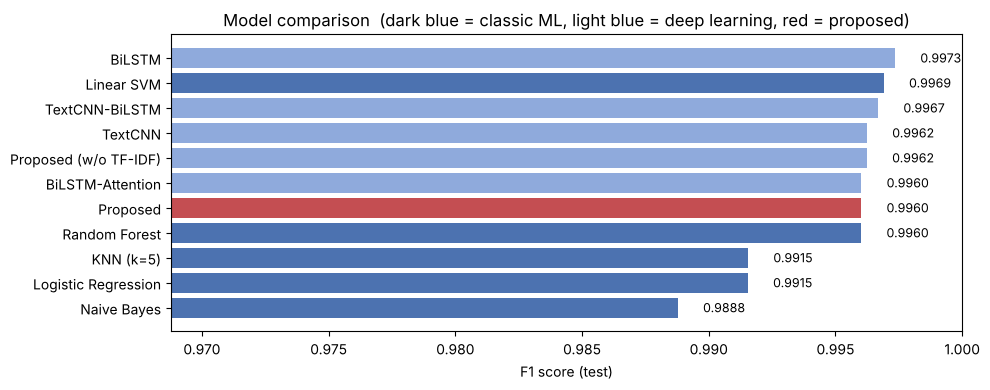

In [14]:
fig, ax = plt.subplots(figsize=(10, 4))
order = res.sort_values("F1").index
ax.barh(order, res.loc[order, "F1"], color=["#C44E52" if k == "Proposed" else
                                              ("#4C72B0" if k in classic else "#8FAADC") for k in order])
lo = res.F1.min()
ax.set_xlim(max(0.0, lo - 0.02), 1.0)
for i, k in enumerate(order):
    ax.text(res.loc[k, "F1"] + 0.001, i, f"{res.loc[k, 'F1']:.4f}", va="center", fontsize=9)
ax.set_xlabel("F1 score (test)")
ax.set_title("Model comparison  (dark blue = classic ML, light blue = deep learning, red = proposed)")
plt.tight_layout()
plt.savefig(RESULTS_DIR / "f1_comparison.png", dpi=120)
plt.show()

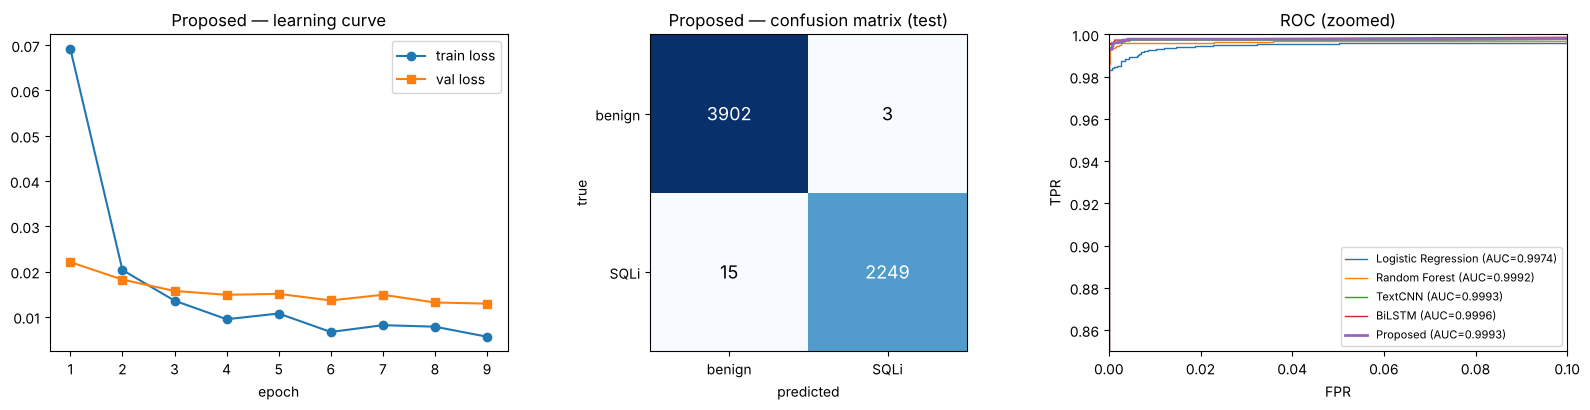

In [15]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.2))
h = histories["Proposed"]
ax[0].plot(h.epoch, h.train_loss, "o-", label="train loss")
ax[0].plot(h.epoch, h.val_loss, "s-", label="val loss")
ax[0].set_title("Proposed — learning curve")
ax[0].set_xlabel("epoch")
ax[0].legend()

pred = (test_scores["Proposed"] >= 0.5).astype(int)
cm = confusion_matrix(y_test, pred)
ax[1].imshow(cm, cmap="Blues")
for (i, j), v in np.ndenumerate(cm):
    ax[1].text(j, i, f"{v}", ha="center", va="center", color="white" if v > cm.max() / 2 else "black", fontsize=13)
ax[1].set_xticks([0, 1], ["benign", "SQLi"])
ax[1].set_yticks([0, 1], ["benign", "SQLi"])
ax[1].set_xlabel("predicted")
ax[1].set_ylabel("true")
ax[1].set_title("Proposed — confusion matrix (test)")

for name in ["Logistic Regression", "Random Forest", "TextCNN", "BiLSTM", "Proposed"]:
    fpr, tpr, _ = roc_curve(y_test, test_scores[name])
    ax[2].plot(fpr, tpr, lw=2 if name == "Proposed" else 1, label=f"{name} (AUC={results[name]['AUC']:.4f})")
ax[2].set_xlim(0, 0.1)
ax[2].set_ylim(0.85, 1.0)
ax[2].set_xlabel("FPR")
ax[2].set_ylabel("TPR")
ax[2].set_title("ROC (zoomed)")
ax[2].legend(fontsize=8, loc="lower right")
plt.tight_layout()
plt.savefig(RESULTS_DIR / "proposed_curves.png", dpi=120)
plt.show()

<div dir="rtl">

## ۸. تحلیل خطا و تفسیرپذیری با Attention

وزن‌های attention نشان می‌دهند مدل هنگام تصمیم‌گیری به کدام توکن‌ها بیشتر توجه کرده است.

</div>

In [16]:
model = dl_models["Proposed"].eval()
p = test_scores["Proposed"]
err = test_df.assign(prob=p, pred=(p >= 0.5).astype(int))
err = err[err.pred != err.Label]
print(f"misclassified: {len(err)} / {len(test_df)}  "
      f"(FP={((err.pred == 1) & (err.Label == 0)).sum()}, FN={((err.pred == 0) & (err.Label == 1)).sum()})")
pd.set_option("display.max_colwidth", 120)
err[["Query", "Label", "prob"]].head(15)

misclassified: 18 / 6169  (FP=3, FN=15)


,Query,Label,prob
1,create user name identified by pass123 temporary tablespace temp default tablespace users;,1,0.000123
11972,roca,0,0.805419
237,â or 3 = 3 --,1,0.035154
19249,%7C,1,0.345663
424,or 'whatever' in ( 'whatever' ),1,0.152659
812,limit,1,0.474024
25,insert,1,0.445034
19237,os,1,0.000663
540,select name from syscolumns where id = ( sele ...,1,0.085209
19224,grant connect to name; grant resource to name;,1,0.000001


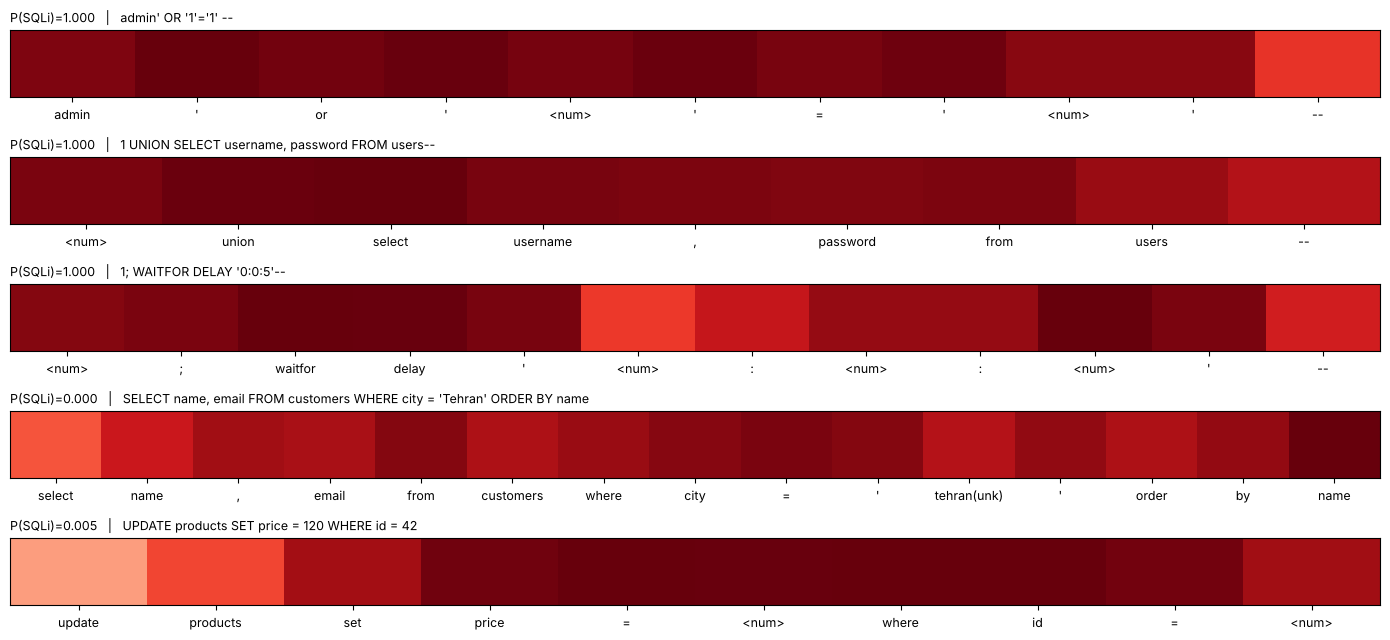

In [17]:
@torch.no_grad()
def explain(query):
    toks = sql_tokenize(query)
    ids, w = encode(toks)
    logit, alpha = model(torch.tensor([ids], device=DEVICE), torch.tensor(np.array([w]), device=DEVICE))
    return torch.sigmoid(logit).item(), [itos[i] if i != 1 else f"{t}(unk)" for i, t in zip(ids, toks)], alpha[0].cpu().numpy()


examples = [
    "admin' OR '1'='1' -- ",
    "1 UNION SELECT username, password FROM users--",
    "1; WAITFOR DELAY '0:0:5'--",
    "SELECT name, email FROM customers WHERE city = 'Tehran' ORDER BY name",
    "UPDATE products SET price = 120 WHERE id = 42",
]
fig, axes = plt.subplots(len(examples), 1, figsize=(14, 1.3 * len(examples)))
for ax, q in zip(axes, examples):
    prob, toks, a = explain(q)
    ax.imshow(a[None, :], cmap="Reds", aspect="auto", vmin=0)
    ax.set_xticks(range(len(toks)), toks, fontsize=9)
    ax.set_yticks([])
    ax.set_title(f"P(SQLi)={prob:.3f}   |   {q}", fontsize=9, loc="left")
plt.tight_layout()
plt.savefig(RESULTS_DIR / "attention_examples.png", dpi=120)
plt.show()

<div dir="rtl">

## ۹. ذخیره‌ی مدل و پیش‌بینی روی کوئری جدید

</div>

In [18]:
torch.save(dict(state_dict=model.state_dict(), cfg=CFG, variant=VARIANTS["Proposed"], itos=itos, idf=idf,
                emb_shape=emb_matrix.shape), MODEL_DIR / "sqli_textcnn_bilstm_att.pt")
print("saved:", MODEL_DIR / "sqli_textcnn_bilstm_att.pt",
      f"({(MODEL_DIR / 'sqli_textcnn_bilstm_att.pt').stat().st_size / 1e6:.1f} MB)")


def load_detector(path=MODEL_DIR / "sqli_textcnn_bilstm_att.pt"):
    # rebuilds the model from the checkpoint alone (vocabulary + idf are stored inside it)
    ck = torch.load(path, map_location=DEVICE, weights_only=False)
    net = SQLiNet(np.zeros(ck["emb_shape"], dtype=np.float32), ck["cfg"], **ck["variant"]).to(DEVICE)
    net.load_state_dict(ck["state_dict"])
    net.eval()
    vocab, idf_ = {t: i for i, t in enumerate(ck["itos"])}, ck["idf"]

    @torch.no_grad()
    def detect(queries, threshold=0.5):
        out = []
        for q in queries:
            ids = [vocab.get(t, 1) for t in sql_tokenize(q)[:ck["cfg"]["max_len"]]] or [1]
            tf = Counter(ids)
            w = np.array([tf[i] / len(ids) * idf_[i] for i in ids], dtype=np.float32)
            logit, _ = net(torch.tensor([ids], device=DEVICE), torch.tensor(w / w.mean(), device=DEVICE)[None])
            prob = torch.sigmoid(logit).item()
            out.append(dict(query=q, p_sqli=round(prob, 4), verdict="SQLi" if prob >= threshold else "benign"))
        return pd.DataFrame(out)
    return detect


detect = load_detector()
detect([
    "SELECT * FROM orders WHERE customer_id = 1024",
    "' OR 1=1#",
    "1' AND SLEEP(5) AND '1'='1",
    "INSERT INTO logs (level, msg) VALUES ('info', 'user logged in')",
    "1 AND extractvalue(1, concat(0x7e, (SELECT database())))",
    "hello world",
])

saved: /home/user/DeetectionPedar/models/sqli_textcnn_bilstm_att.pt (4.0 MB)


,query,p_sqli,verdict
0,SELECT * FROM orders WHERE customer_id = 1024,0.0000,benign
1,' OR 1=1#,1.0000,SQLi
2,1' AND SLEEP(5) AND '1'='1,1.0000,SQLi
3,"INSERT INTO logs (level, msg) VALUES ('info', 'user logged in')",0.0002,benign
4,"1 AND extractvalue(1, concat(0x7e, (SELECT database())))",1.0000,SQLi
5,hello world,0.0005,benign


<div dir="rtl">

## ۱۰. جمع‌بندی و تحلیل نتایج

**نتایج روی داده‌ی test (۶٬۱۶۹ کوئری):**

| مدل | F1 | Accuracy | FPR | FNR |
|---|---|---|---|---|
| **Proposed (میانگین ۳ seed)** | **0.9969 ± 0.0008** | 0.9977 | 0.0004 | 0.0055 |
| BiLSTM | 0.9973 | 0.9981 | 0.0008 | 0.0040 |
| Linear SVM (TF-IDF) | 0.9969 | 0.9977 | 0.0005 | 0.0053 |
| Random Forest (TF-IDF) | 0.9960 | 0.9971 | 0.0005 | 0.0071 |
| KNN (TF-IDF) | 0.9915 | 0.9938 | 0.0008 | 0.0155 |

**تحلیل صادقانه:**
1. مدل پیشنهادی به F1 حدود **۹۹.۷٪** رسید، یعنی از گزارش خود مقاله (F1 = 95.64% روی دیتاست خصوصی‌شان) بالاتر است. ولی این دو عدد **قابل مقایسه‌ی مستقیم نیستند**، چون دیتاست‌ها فرق دارند.
2. روی این دیتاست **همه‌ی مدل‌های قوی به سقف رسیده‌اند** (F1 بین 0.996 تا 0.997). اختلاف ۰.۰۰۱ در F1 فقط حدود ۲ تا ۳ نمونه‌ی test است و اختلاف بین seed های مختلف مدل پیشنهادی (±0.0008) هم‌اندازه‌ی اختلاف بین مدل‌هاست. پس روی این دیتاست **برتری معنادار** مدل پیشنهادی نسبت به BiLSTM یا Linear SVM اثبات نمی‌شود.
3. مزیت روش‌های عمیق در این آزمایش «دقت بیشتر» نیست. مزیتشان این است که مهندسی ویژگی دستی لازم ندارند، AUC بالاتری نسبت به روش‌های کلاسیک دارند (۰.۹۹۹ در برابر ۰.۹۹۷ برای Logistic Regression) و اگر با دیتاست بزرگ‌تر و پیچیده‌تر آموزش ببینند، به حملات مبهم‌سازی‌شده بهتر تعمیم پیدا می‌کنند.
4. بیشتر خطاها (بخش ۸) روی کوئری‌های **تک‌کلمه‌ای یا مبهم** هستند (مثل `limit`، `insert`، `os`، `%7C`) که برچسبشان در خود دیتاست بحث‌برانگیز است، یعنی بخشی از خطا از **نویز برچسب** دیتاست می‌آید.
5. وزن‌های attention تقریباً یکنواخت پخش شده‌اند. توضیحش این است که مدل حتی بدون attention هم کوئری‌ها را به‌راحتی جدا می‌کند (همان اشباع بند ۲). Ablation هم همین را نشان می‌دهد: حذف attention یا TF-IDF تأثیر معناداری ندارد.

**پیشنهاد برای کار پژوهشی (پایان‌نامه/مقاله):** برای اینکه برتری مدل دیده شود، باید روی سناریوهای سخت‌تر ارزیابی شود، مثلاً:
- آموزش روی یک دیتاست و تست روی دیتاست دیگر (cross-dataset)؛
- تست روی payload های مبهم‌سازی‌شده (encoding، کامنت‌گذاری، تغییر حروف، WAF-bypass)؛
- گزارش آماری با چند seed یا k-fold و آزمون معناداری (مثلاً McNemar).

</div>

<div dir="rtl">

## منابع

1. **[مقاله‌ی اصلی]** H. Sun, Y. Du, Q. Li, "Deep Learning-Based Detection Technology for SQL Injection Research and Implementation,"
   *Applied Sciences*, 13(16):9466, 2023. https://doi.org/10.3390/app13169466
2. Y. Kim, "Convolutional Neural Networks for Sentence Classification," *EMNLP*, 2014 — پایه‌ی TextCNN.
3. D. Bahdanau, K. Cho, Y. Bengio, "Neural Machine Translation by Jointly Learning to Align and Translate," *ICLR*, 2015 — attention افزایشی.
4. T. Mikolov et al., "Distributed Representations of Words and Phrases and their Compositionality," *NeurIPS*, 2013 — Word2Vec.
5. دیتاست: SQL Injection Dataset (sajid576), Kaggle — https://www.kaggle.com/datasets/sajid576/sql-injection-dataset

</div>